In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("SampleSuperstore.csv")

# Check missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64


In [2]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

print(missing_summary)

              Missing_Count  Missing_Percentage
Ship Mode                 0                 0.0
Segment                   0                 0.0
Country                   0                 0.0
City                      0                 0.0
State                     0                 0.0
Postal Code               0                 0.0
Region                    0                 0.0
Category                  0                 0.0
Sub-Category              0                 0.0
Sales                     0                 0.0
Quantity                  0                 0.0
Discount                  0                 0.0
Profit                    0                 0.0


In [3]:
# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 17


In [4]:
# Display duplicate rows, if any
duplicates = df[df.duplicated()]

print("Duplicate rows:")
print(duplicates)

Duplicate rows:
           Ship Mode      Segment        Country           City         State  \
950   Standard Class  Home Office  United States   Philadelphia  Pennsylvania   
3406  Standard Class  Home Office  United States       Columbus          Ohio   
3670  Standard Class     Consumer  United States          Salem        Oregon   
4117  Standard Class     Consumer  United States    Los Angeles    California   
4553  Standard Class     Consumer  United States  San Francisco    California   
5905        Same Day  Home Office  United States  San Francisco    California   
6146  Standard Class    Corporate  United States  San Francisco    California   
6334  Standard Class     Consumer  United States  New York City      New York   
6357  Standard Class    Corporate  United States        Seattle    Washington   
7608  Standard Class     Consumer  United States  San Francisco    California   
7735  Standard Class    Corporate  United States        Seattle    Washington   
7759  Standa

In [5]:
# Calculate duplicate percentage
duplicate_percentage = (duplicate_count / len(df)) * 100

print("Total rows:", len(df))
print("Duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_percentage, 2), "%")

Total rows: 9994
Duplicate rows: 17
Duplicate percentage: 0.17 %


In [6]:
# Check numerical columns for range issues
print("Minimum values:")
print(df.select_dtypes(include='number').min())

print("\nMaximum values:")
print(df.select_dtypes(include='number').max())

Minimum values:
Postal Code    1040.000
Sales             0.444
Quantity          1.000
Discount          0.000
Profit        -6599.978
dtype: float64

Maximum values:
Postal Code    99301.000
Sales          22638.480
Quantity          14.000
Discount           0.800
Profit          8399.976
dtype: float64


In [7]:
# Check outliers using IQR

numerical_columns = ['Sales', 'Quantity', 'Discount', 'Profit']

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    print(f"\n{col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


Sales
Lower Bound: -271.71000000000004
Upper Bound: 498.93
Number of Outliers: 1167

Quantity
Lower Bound: -2.5
Upper Bound: 9.5
Number of Outliers: 170

Discount
Lower Bound: -0.30000000000000004
Upper Bound: 0.5
Number of Outliers: 856

Profit
Lower Bound: -39.724125
Upper Bound: 70.816875
Number of Outliers: 1881


In [8]:
# Inspect outlier records without removing them
numerical_columns = ['Sales', 'Quantity', 'Discount', 'Profit']
for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print("\n" + "=" * 60)
    print(f"{col} - Outlier Sample")
    print("=" * 60)
    print(outliers[[col, 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']].head(10))


Sales - Outlier Sample
        Sales         Category Sub-Category      Sales  Quantity  Discount  \
1    731.9400        Furniture       Chairs   731.9400         3      0.00   
3    957.5775        Furniture       Tables   957.5775         5      0.45   
7    907.1520       Technology       Phones   907.1520         6      0.20   
10  1706.1840        Furniture       Tables  1706.1840         9      0.20   
11   911.4240       Technology       Phones   911.4240         4      0.20   
16   665.8800  Office Supplies      Storage   665.8800         6      0.00   
24  1044.6300        Furniture       Tables  1044.6300         3      0.00   
27  3083.4300        Furniture    Bookcases  3083.4300         7      0.50   
35  1097.5440       Technology       Phones  1097.5440         7      0.20   
38   532.3992        Furniture    Bookcases   532.3992         3      0.32   

       Profit  
1    219.5820  
3   -383.0310  
7     90.7152  
10    85.3092  
11    68.3568  
16    13.3176  
24   

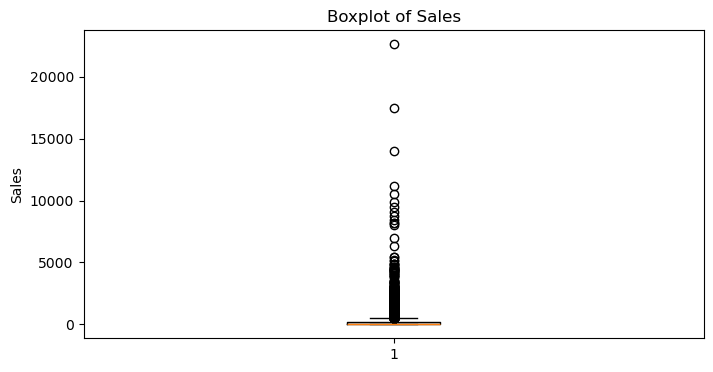

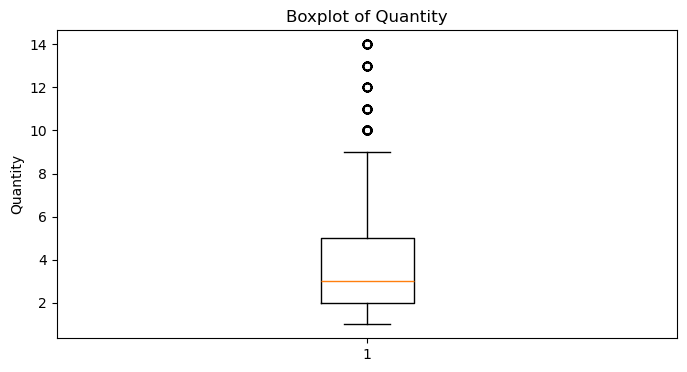

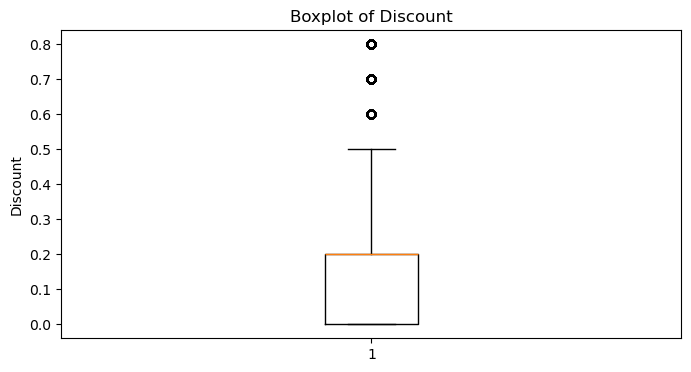

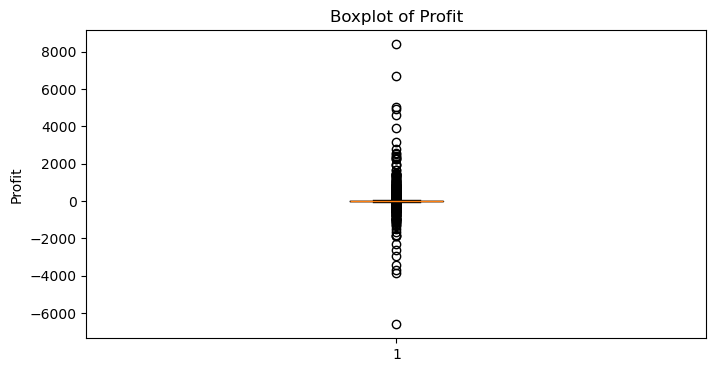

In [9]:
import matplotlib.pyplot as plt

numerical_columns = ['Sales', 'Quantity', 'Discount', 'Profit']

for col in numerical_columns:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col])
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)
    plt.show()

In [10]:
# Remove exact duplicate rows

before_rows = len(df)

df_clean = df.drop_duplicates().copy()

after_rows = len(df_clean)

print("Rows before removing duplicates:", before_rows)
print("Duplicate rows removed:", before_rows - after_rows)
print("Rows after removing duplicates:", after_rows)

Rows before removing duplicates: 9994
Duplicate rows removed: 17
Rows after removing duplicates: 9977


In [11]:
# Verify duplicate rows after cleaning

remaining_duplicates = df_clean.duplicated().sum()

print("Remaining duplicate rows:", remaining_duplicates)

Remaining duplicate rows: 0


In [12]:
# Check cleaned dataset dimensions

print("Rows in cleaned dataset:", df_clean.shape[0])
print("Columns in cleaned dataset:", df_clean.shape[1])

Rows in cleaned dataset: 9977
Columns in cleaned dataset: 13


In [13]:
# Check column names and data types

print("Column names:")
print(df_clean.columns)

print("\nData types:")
print(df_clean.dtypes)

Column names:
Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

Data types:
Ship Mode        object
Segment          object
Country          object
City             object
State            object
Postal Code       int64
Region           object
Category         object
Sub-Category     object
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object


In [14]:
# Check unique values in categorical columns

categorical_columns = [
    'Ship Mode',
    'Segment',
    'Country',
    'Region',
    'Category',
    'Sub-Category'
]

for col in categorical_columns:
    print("\n" + "=" * 50)
    print(f"{col} - Unique Values")
    print("=" * 50)
    print(df_clean[col].unique())


Ship Mode - Unique Values
['Second Class' 'Standard Class' 'First Class' 'Same Day']

Segment - Unique Values
['Consumer' 'Corporate' 'Home Office']

Country - Unique Values
['United States']

Region - Unique Values
['South' 'West' 'Central' 'East']

Category - Unique Values
['Furniture' 'Office Supplies' 'Technology']

Sub-Category - Unique Values
['Bookcases' 'Chairs' 'Labels' 'Tables' 'Storage' 'Furnishings' 'Art'
 'Phones' 'Binders' 'Appliances' 'Paper' 'Accessories' 'Envelopes'
 'Fasteners' 'Supplies' 'Machines' 'Copiers']


In [15]:
# Check missing values in the cleaned dataset

print("Missing values in each column:")
print(df_clean.isnull().sum())

print("\nTotal missing values:")
print(df_clean.isnull().sum().sum())

Missing values in each column:
Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

Total missing values:
0


In [16]:
# Check for invalid negative values

print("Negative Sales:", (df_clean['Sales'] < 0).sum())
print("Negative Quantity:", (df_clean['Quantity'] < 0).sum())
print("Negative Discount:", (df_clean['Discount'] < 0).sum())
print("Negative Profit:", (df_clean['Profit'] < 0).sum())

Negative Sales: 0
Negative Quantity: 0
Negative Discount: 0
Negative Profit: 1869


In [17]:
# Inspect negative-profit records

negative_profit = df_clean[df_clean['Profit'] < 0]

print("Number of negative-profit records:", len(negative_profit))
print("\nSample negative-profit records:")
print(negative_profit[['Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']].head(10))

Number of negative-profit records: 1869

Sample negative-profit records:
           Category Sub-Category      Sales  Quantity  Discount     Profit
3         Furniture       Tables   957.5775         5      0.45  -383.0310
14  Office Supplies   Appliances    68.8100         5      0.80  -123.8580
15  Office Supplies      Binders     2.5440         3      0.80    -3.8160
23        Furniture       Chairs    71.3720         2      0.30    -1.0196
27        Furniture    Bookcases  3083.4300         7      0.50 -1665.0522
28  Office Supplies      Binders     9.6180         2      0.70    -7.0532
32  Office Supplies      Binders     6.8580         6      0.70    -5.7150
36        Furniture  Furnishings   190.9200         5      0.60  -147.9630
38        Furniture    Bookcases   532.3992         3      0.32   -46.9764
39        Furniture       Chairs   212.0580         3      0.30   -15.1470


In [18]:
# Check records with unusually high discounts

high_discount = df_clean[df_clean['Discount'] > 0.5]

print("Records with discount greater than 50%:", len(high_discount))

print("\nHigh-discount records:")
print(high_discount[
    ['Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']
].head(10))

Records with discount greater than 50%: 855

High-discount records:
            Category Sub-Category    Sales  Quantity  Discount    Profit
14   Office Supplies   Appliances   68.810         5       0.8 -123.8580
15   Office Supplies      Binders    2.544         3       0.8   -3.8160
28   Office Supplies      Binders    9.618         2       0.7   -7.0532
32   Office Supplies      Binders    6.858         6       0.7   -5.7150
36         Furniture  Furnishings  190.920         5       0.6 -147.9630
75   Office Supplies      Binders    1.248         3       0.8   -1.9344
76         Furniture  Furnishings    9.708         3       0.6   -5.8248
78         Furniture  Furnishings   19.300         5       0.6  -14.4750
95   Office Supplies      Binders    5.682         1       0.7   -3.7880
101  Office Supplies      Binders    1.788         3       0.8   -3.0396


In [19]:
# Task 24 - Start Data Quality Audit
print("Data Quality Audit started")
print("Dataset shape:", df_clean.shape)
print("Columns:", list(df_clean.columns))

Data Quality Audit started
Dataset shape: (9977, 13)
Columns: ['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']


In [20]:
# Check duplicate rows

duplicate_count = df_clean.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [21]:
# Check data types

print("Data types of each column:")
print(df_clean.dtypes)


Data types of each column:
Ship Mode        object
Segment          object
Country          object
City             object
State            object
Postal Code       int64
Region           object
Category         object
Sub-Category     object
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object


In [22]:
# Check invalid/range values

print("Sales <= 0:", (df_clean['Sales'] <= 0).sum())
print("Quantity <= 0:", (df_clean['Quantity'] <= 0).sum())
print("Discount < 0:", (df_clean['Discount'] < 0).sum())
print("Discount > 1:", (df_clean['Discount'] > 1).sum())

Sales <= 0: 0
Quantity <= 0: 0
Discount < 0: 0
Discount > 1: 0


In [23]:
# Check consistency issues

print("Profit greater than Sales:", (df_clean['Profit'] > df_clean['Sales']).sum())
print("Quantity is not positive:", (df_clean['Quantity'] <= 0).sum())
print("Discount outside 0-1 range:", ((df_clean['Discount'] < 0) | (df_clean['Discount'] > 1)).sum())
print("Sales with zero Quantity:", ((df_clean['Sales'] > 0) & (df_clean['Quantity'] == 0)).sum())

Profit greater than Sales: 0
Quantity is not positive: 0
Discount outside 0-1 range: 0
Sales with zero Quantity: 0


In [24]:
# Step 6 - Quantify data quality issues

print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

print("Sales <= 0:", (df_clean['Sales'] <= 0).sum())
print("Quantity <= 0:", (df_clean['Quantity'] <= 0).sum())
print("Discount < 0:", (df_clean['Discount'] < 0).sum())
print("Discount > 1:", (df_clean['Discount'] > 1).sum())

print("Profit greater than Sales:", 
      (df_clean['Profit'] > df_clean['Sales']).sum())

print("Sales with zero Quantity:", 
      ((df_clean['Sales'] > 0) & (df_clean['Quantity'] == 0)).sum())

Missing values: 0
Duplicate rows: 0
Sales <= 0: 0
Quantity <= 0: 0
Discount < 0: 0
Discount > 1: 0
Profit greater than Sales: 0
Sales with zero Quantity: 0


In [25]:
# Step 7 - Create cleaned sample

cleaned_sample = df_clean.head(100)

print("Cleaned sample shape:", cleaned_sample.shape)
print("\nCleaned sample:")
display(cleaned_sample)

Cleaned sample shape: (100, 13)

Cleaned sample:


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,Standard Class,Home Office,United States,Portland,Oregon,97206,West,Office Supplies,Binders,5.6820,1,0.70,-3.7880
96,Second Class,Home Office,United States,New York City,New York,10009,East,Furniture,Furnishings,96.5300,7,0.00,40.5426
97,First Class,Consumer,United States,San Francisco,California,94122,West,Office Supplies,Binders,51.3120,3,0.20,17.9592
98,Standard Class,Corporate,United States,Saint Paul,Minnesota,55106,Central,Office Supplies,Appliances,77.8800,6,0.00,22.5852


In [26]:
# Step 8 - Create audit report

audit_report = pd.DataFrame({
    'Issue': [
        'Missing values',
        'Duplicate rows',
        'Sales <= 0',
        'Quantity <= 0',
        'Discount < 0',
        'Discount > 1',
        'Profit greater than Sales',
        'Sales with zero Quantity'
    ],
    'Count': [
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum(),
        (df_clean['Sales'] <= 0).sum(),
        (df_clean['Quantity'] <= 0).sum(),
        (df_clean['Discount'] < 0).sum(),
        (df_clean['Discount'] > 1).sum(),
        (df_clean['Profit'] > df_clean['Sales']).sum(),
        ((df_clean['Sales'] > 0) & (df_clean['Quantity'] == 0)).sum()
    ]
})

print("Data Quality Audit Report:")
display(audit_report)

Data Quality Audit Report:


,Issue,Count
0,Missing values,0
1,Duplicate rows,0
2,Sales <= 0,0
3,Quantity <= 0,0
4,Discount < 0,0
5,Discount > 1,0
6,Profit greater than Sales,0
7,Sales with zero Quantity,0


In [27]:
# Step 9 - Create issue log

issue_log = audit_report.copy()

issue_log['Status'] = issue_log['Count'].apply(
    lambda x: 'No Issue' if x == 0 else 'Issue Found'
)

issue_log['Action'] = issue_log['Count'].apply(
    lambda x: 'No action required' if x == 0 else 'Review and investigate'
)

print("Data Quality Issue Log:")
display(issue_log)

Data Quality Issue Log:


,Issue,Count,Status,Action
0,Missing values,0,No Issue,No action required
1,Duplicate rows,0,No Issue,No action required
2,Sales <= 0,0,No Issue,No action required
3,Quantity <= 0,0,No Issue,No action required
4,Discount < 0,0,No Issue,No action required
5,Discount > 1,0,No Issue,No action required
6,Profit greater than Sales,0,No Issue,No action required
7,Sales with zero Quantity,0,No Issue,No action required


In [28]:
# Step 10 - Save audit log

audit_log_file = "data_quality_issue_log.csv"

issue_log.to_csv(audit_log_file, index=False)

print("Audit log created successfully.")
print("File:", audit_log_file)

Audit log created successfully.
File: data_quality_issue_log.csv


In [29]:
# Step 11 - Verify audit log

print("Audit log preview:")
display(pd.read_csv(audit_log_file))

Audit log preview:


,Issue,Count,Status,Action
0,Missing values,0,No Issue,No action required
1,Duplicate rows,0,No Issue,No action required
2,Sales <= 0,0,No Issue,No action required
3,Quantity <= 0,0,No Issue,No action required
4,Discount < 0,0,No Issue,No action required
5,Discount > 1,0,No Issue,No action required
6,Profit greater than Sales,0,No Issue,No action required
7,Sales with zero Quantity,0,No Issue,No action required


In [30]:
# Step 12 - Prepare README summary

readme_summary = f"""
# Data Quality Audit Report

## Dataset Summary
- Rows: {df_clean.shape[0]}
- Columns: {df_clean.shape[1]}

## Audit Results
- Missing values: {df_clean.isnull().sum().sum()}
- Duplicate rows: {df_clean.duplicated().sum()}
- Sales <= 0: {(df_clean['Sales'] <= 0).sum()}
- Quantity <= 0: {(df_clean['Quantity'] <= 0).sum()}
- Discount < 0: {(df_clean['Discount'] < 0).sum()}
- Discount > 1: {(df_clean['Discount'] > 1).sum()}
- Profit greater than Sales: {(df_clean['Profit'] > df_clean['Sales']).sum()}
- Sales with zero Quantity: {((df_clean['Sales'] > 0) & (df_clean['Quantity'] == 0)).sum()}

## Conclusion
All audited data-quality checks returned zero issues.
No corrective action was required.
"""

print(readme_summary)


# Data Quality Audit Report

## Dataset Summary
- Rows: 9977
- Columns: 13

## Audit Results
- Missing values: 0
- Duplicate rows: 0
- Sales <= 0: 0
- Quantity <= 0: 0
- Discount < 0: 0
- Discount > 1: 0
- Profit greater than Sales: 0
- Sales with zero Quantity: 0

## Conclusion
All audited data-quality checks returned zero issues.
No corrective action was required.



In [31]:
# Step 13 - Save README file

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_summary)

print("README.md created successfully.")
print("File: README.md")

README.md created successfully.
File: README.md


In [1]:
import os
print(os.getcwd())

C:\Users\DELL\Documents\Veda_Task24
